# How `Qdrant/BM25` compute the sparse vector

In [2]:
from collections import Counter
from fastembed.sparse import SparseTextEmbedding


model = SparseTextEmbedding("Qdrant/bm25")
bm25 = model.model

text = """A retrospective analysis was conducted on 332 adult patients who were diagnosed with AMI-CS."""

vec = next(model.embed([text]))
print(f"Text: {text} \nLength of text: {len(text)}\n")
print("=== Sparse vector ===")
print("indices:", vec.indices)
print("values:", vec.values)
print("non-zero dimensions:", len(vec.indices))


# Use FastEmbed's real internal BM25 preprocessing
tokens = bm25.tokenizer.tokenize(text.lower())

# Remove stopwords
tokens_no_stopwords = [
    token for token in tokens
    if token not in bm25.stopwords
]

# Stem correctly: pass a list, not one string
if not bm25.disable_stemmer:
    final_terms = bm25._stem(tokens_no_stopwords)
else:
    final_terms = tokens_no_stopwords

# Compute ids from final terms
term_counts = Counter(final_terms)

index_to_value = {
    int(i): float(v)
    for i, v in zip(vec.indices, vec.values)
}

print("\n=== Included terms ===")
print(f"{'term':<40} {'count':<8} {'index':<15} {'value'}")
print("-" * 60)

for term, count in term_counts.items():
    idx = int(bm25.compute_token_id(term))
    value = index_to_value.get(idx, 0.0)

    print(f"{term:<40} {count:<8} {idx:<15} {value}")


print("\n=== Dropped stopwords ===")
dropped = [
    token for token in tokens
    if token in bm25.stopwords
]
print(dropped)

Text: A retrospective analysis was conducted on 332 adult patients who were diagnosed with AMI-CS. 
Length of text: 92

=== Sparse vector ===
indices: [1471019746 1298296063  938217065  390168769  801873620 1796268431
 1714506967 1035623941 1270418937]
values: [1.65209739 1.65209739 1.65209739 1.65209739 1.65209739 1.65209739
 1.65209739 1.65209739 1.65209739]
non-zero dimensions: 9

=== Included terms ===
term                                     count    index           value
------------------------------------------------------------
retrospect                               1        1471019746      1.6520973892637139
analysi                                  1        1298296063      1.6520973892637139
conduct                                  1        938217065       1.6520973892637139
332                                      1        390168769       1.6520973892637139
adult                                    1        801873620       1.6520973892637139
patient                         

In [9]:
import math
from collections import Counter
from qdrant_client import QdrantClient, models
from fastembed.sparse import SparseTextEmbedding

model = SparseTextEmbedding("Qdrant/bm25")
bm25 = model.model

# A small toy corpus so we actually have document-frequency stats to work with
corpus = [
    "A retrospective analysis was conducted on 332 adult patients who were diagnosed with AMI-CS.",
    "Cardiogenic shock patients often require mechanical circulatory support.",
    "AMI-CS carries a high in-hospital mortality rate despite advances in treatment.",
    "This retrospective cohort study analyzed adult patients over five years.",
]

# --- Spin up an in-memory Qdrant instance ---
client = QdrantClient(":memory:")
client.create_collection(
    collection_name="demo",
    sparse_vectors_config={
        "bm25": models.SparseVectorParams(modifier=models.Modifier.IDF)
    },
)

client.upsert(
    collection_name="demo",
    points=[
        models.PointStruct(
            id=i,
            payload={"text": doc},
            vector={"bm25": models.Document(text=doc, model="Qdrant/bm25")},
        )
        for i, doc in enumerate(corpus)
    ],
)

# --- Manually compute IDF the same way Qdrant does, for comparison ---
N = len(corpus)
doc_freq = Counter()  # how many documents each token_id appears in

# embed each document and count how many documents each token_id appears in
for doc in corpus:
    vec = next(model.embed([doc]))
    print(f"Document: {doc}\nIndices: {vec.indices}\n")
    for idx in vec.indices:
        doc_freq[int(idx)] += 1

def qdrant_idf(n_qi, N):
    return math.log((N - n_qi + 0.5) / (n_qi + 0.5) + 1)

print(f"Corpus size N = {N}\n")
print(f"{'term_id':<15}{'doc_freq n(qi)':<18}{'IDF':<10}")
print("-" * 45)
for term_id, n_qi in sorted(doc_freq.items(), key=lambda x: -x[1]):
    print(f"{term_id:<15}{n_qi:<18}{qdrant_idf(n_qi, N):<10.4f}")

# --- Sanity check: run a real query and see the combined BM25 score Qdrant returns ---
query = "retrospective adult patients"
results = client.query_points(
    collection_name="demo",
    query=models.Document(text=query, model="Qdrant/bm25"),
    using="bm25",
    limit=len(corpus),
).points

print("\n=== Qdrant search results (full BM25 score = TF x IDF) ===")
for r in results:
    print(f"score={r.score:.4f}  doc={r.payload['text'][:60]}...")

Document: A retrospective analysis was conducted on 332 adult patients who were diagnosed with AMI-CS.
Indices: [1471019746 1298296063  938217065  390168769  801873620 1796268431
 1714506967 1035623941 1270418937]

Document: Cardiogenic shock patients often require mechanical circulatory support.
Indices: [1064233887 1999205350 1796268431 1285937727  516115046 1207498445
  574692281 1100855371]

Document: AMI-CS carries a high in-hospital mortality rate despite advances in treatment.
Indices: [1035623941 1270418937 1523874731 1612531086  291013412  547113685
 1151308235  663941294  728487644 2114294529]

Document: This retrospective cohort study analyzed adult patients over five years.
Indices: [1471019746 1525777304  150760872  412527760  801873620 1796268431
  297260153  822745112]

Corpus size N = 4

term_id        doc_freq n(qi)    IDF       
---------------------------------------------
1796268431     3                 0.3567    
1471019746     2                 0.6931    
8018736

In [12]:
import math
from collections import Counter
from qdrant_client import QdrantClient, models
from fastembed.sparse import SparseTextEmbedding

model = SparseTextEmbedding("Qdrant/bm25")
bm25 = model.model

corpus = [
    "A retrospective analysis was conducted on 332 adult patients who were diagnosed with AMI-CS.",
    "Cardiogenic shock patients often require mechanical circulatory support.",
    "AMI-CS carries a high in-hospital mortality rate despite advances in treatment.",
    "This retrospective cohort study analyzed adult patients over five years.",
]

# --- Spin up an in-memory Qdrant instance ---
client = QdrantClient(":memory:")
client.create_collection(
    collection_name="demo",
    sparse_vectors_config={
        "bm25": models.SparseVectorParams(modifier=models.Modifier.IDF)
    },
)
client.upsert(
    collection_name="demo",
    points=[
        models.PointStruct(
            id=i,
            payload={"text": doc},
            vector={"bm25": models.Document(text=doc, model="Qdrant/bm25")},
        )
        for i, doc in enumerate(corpus)
    ],
)

# --- Manually replicate preprocessing per document to track terms, ids, and stopwords ---
N = len(corpus)
doc_freq = Counter()       # term -> number of docs it appears in
term_to_id = {}            # term -> hashed id (for display)
dropped_stopwords_per_doc = []

for doc in corpus:
    tokens = bm25.tokenizer.tokenize(doc.lower())

    dropped = [t for t in tokens if t in bm25.stopwords]
    dropped_stopwords_per_doc.append(dropped)

    kept = [t for t in tokens if t not in bm25.stopwords]
    stemmed = bm25._stem(kept) if not bm25.disable_stemmer else kept

    unique_terms_in_doc = set(stemmed)
    for term in unique_terms_in_doc:
        # calculate document frequency for each term (n(qi))
        doc_freq[term] += 1
        # to map term to its hashed id for display purposes
        term_to_id[term] = int(bm25.compute_token_id(term))

# --- Compute IDF using Qdrant's formula ---
def qdrant_idf(n_qi, N):
    return math.log((N - n_qi + 0.5) / (n_qi + 0.5) + 1)

# --- Print term / id / doc_freq / IDF table ---
print(f"Corpus size N = {N}\n")
print(f"{'term':<18}{'term_id':<15}{'doc_freq n(qi)':<18}{'IDF':<10}")
print("-" * 61)
for term, n_qi in sorted(doc_freq.items(), key=lambda x: -x[1]):
    idf = qdrant_idf(n_qi, N)
    print(f"{term:<18}{term_to_id[term]:<15}{n_qi:<18}{idf:<10.4f}")

# --- Print dropped stopwords per document ---
print("\n=== Dropped stopwords per document ===")
for i, (doc, dropped) in enumerate(zip(corpus, dropped_stopwords_per_doc)):
    print(f"[doc {i}] {doc[:60]}...")
    print(f"Dropped stopwords: {dropped}\n")

# --- Sanity check against real Qdrant search score ---
query = "retrospective adult patients"
results = client.query_points(
    collection_name="demo",
    query=models.Document(text=query, model="Qdrant/bm25"),
    using="bm25",
    limit=len(corpus),
).points

print("=== Qdrant search results (full BM25 score = TF x IDF) ===")
for r in results:
    print(f"score={r.score:.4f}  doc={r.payload['text'][:60]}...")

Corpus size N = 4

term              term_id        doc_freq n(qi)    IDF       
-------------------------------------------------------------
patient           1796268431     3                 0.3567    
adult             801873620      2                 0.6931    
cs                1270418937     2                 0.6931    
retrospect        1471019746     2                 0.6931    
ami               1035623941     2                 0.6931    
diagnos           1714506967     1                 1.2040    
conduct           938217065      1                 1.2040    
332               390168769      1                 1.2040    
analysi           1298296063     1                 1.2040    
requir            516115046      1                 1.2040    
circulatori       574692281      1                 1.2040    
mechan            1207498445     1                 1.2040    
often             1285937727     1                 1.2040    
cardiogen         1064233887     1                 

# Dense Vector

=== Dense vector ===
Model: nomic-embed-text:latest
Vector shape: (768,)
Number of dimensions: 768
Text: A retrospective analysis was conducted on 332 adult patients who were diagnosed with AMI-CS.
Length of text: 92
First 20 values:
[ 0.12341617  0.47731912 -3.80318975 -0.86197102  0.29201481 -0.09571008
  0.35264501  0.29629505  0.32974315  0.07025451  0.20927286  0.80875099
  1.83334589 -0.70772731 -0.11114966 -1.90498936 -0.26641327 -0.76917195
 -1.31194413  1.27386403]

=== Dense vector stats ===
Min: -3.803189754486084
Max: 1.961925745010376
Mean: 0.005980435071402705
Non-zero values: 768
Zero values: 0


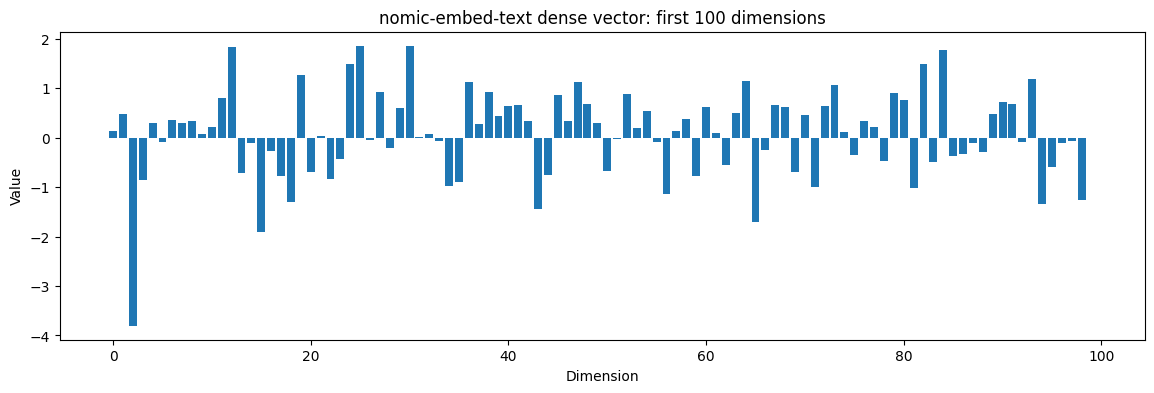

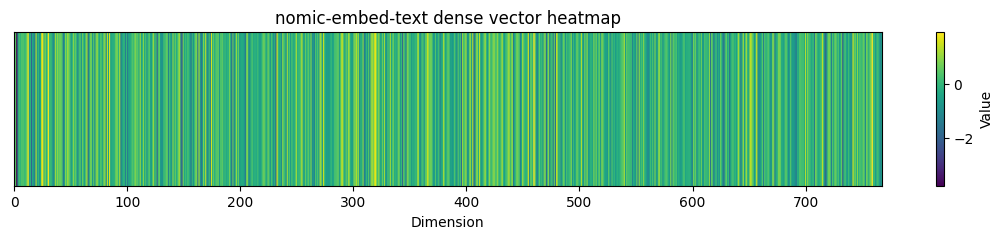

In [2]:
import requests
import numpy as np
import matplotlib.pyplot as plt

text = """A retrospective analysis was conducted on 332 adult patients who were diagnosed with AMI-CS."""

response = requests.post(
    "http://localhost:11434/api/embeddings",
    json={
        "model": "nomic-embed-text:latest",
        "prompt": text,
    },
)

response.raise_for_status()

vec = np.array(response.json()["embedding"])

print("=== Dense vector ===")
print("Model: nomic-embed-text:latest")
print("Vector shape:", vec.shape)
print("Number of dimensions:", len(vec))
print("Text:", text)
print("Length of text:", len(text))
print("First 20 values:")
print(vec[:20])

print("\n=== Dense vector stats ===")
print("Min:", vec.min())
print("Max:", vec.max())
print("Mean:", vec.mean())
print("Non-zero values:", np.count_nonzero(vec))
print("Zero values:", len(vec) - np.count_nonzero(vec))

# Plot first 100 dimensions
n = 100

plt.figure(figsize=(14, 4))
plt.bar(range(n), vec[:n])
plt.title(f"nomic-embed-text dense vector: first {n} dimensions")
plt.xlabel("Dimension")
plt.ylabel("Value")
plt.show()

# Heatmap-like visualization
plt.figure(figsize=(14, 2))
plt.imshow(vec.reshape(1, -1), aspect="auto")
plt.title("nomic-embed-text dense vector heatmap")
plt.xlabel("Dimension")
plt.yticks([])
plt.colorbar(label="Value")
plt.show()

# RAG Evaluation Results v3

This section analyzes the two RAG evaluation result files:

- `llama_3_2_3b__qwen2_5_7b.csv`
- `medllama_2_7b__qwen2_5_7b.csv`

The plots focus on answer quality, retrieval behavior, category-level failure modes, and latency trade-offs. The two runs use the same judge and embedding model, so differences here mostly reflect the response model rather than retrieval configuration.


In [ ]:
from pathlib import Path
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    import seaborn as sns
    sns.set_theme(style="whitegrid", context="notebook")
except ImportError:
    sns = None
    plt.style.use("seaborn-v0_8-whitegrid")

RESULT_DIR = Path("results_v3")
FILES = {
    "Llama 3.2 3B": RESULT_DIR / "llama_3_2_3b__qwen2_5_7b.csv",
    "MedLlama 2 7B": RESULT_DIR / "medllama_2_7b__qwen2_5_7b.csv",
}

QUALITY_METRICS = [
    "correctness_score",
    "faithfulness",
    "answer_relevancy",
    "context_recall",
    "llm_context_precision_with_reference",
]

MODEL_ORDER = list(FILES)
MODEL_COLORS = {
    "Llama 3.2 3B": "#2f80ed",
    "MedLlama 2 7B": "#e76f51",
}

frames = []
for model_name, file_path in FILES.items():
    df = pd.read_csv(file_path)
    df["model"] = model_name
    df["correctness_pct"] = df["correctness_score"] * 100
    df["latency_minutes"] = df["api_latency_seconds"] / 60
    frames.append(df)

results = pd.concat(frames, ignore_index=True)
results["is_correct"] = results["is_correct"].astype(bool)
results.head()

,query_id,eval_unit,paper_index,article_id,article_title,reference_section,reference_status,source_row,api_latency_seconds,retrieved_context_count,...,paper_accuracy,min_paper_correctness,all_papers_correct,query_outcome,response_model,judge_model,embedding_model,model,correctness_pct,latency_minutes
0,1,paper,1,s12873-022-00582-z,Prediction of prognosis in elderly patients wi...,Methods,reported,2,91.713876,1,...,0.083333,0.111111,False,Needs review,llama3.2:3b,qwen2.5:7b,nomic-embed-text:latest,Llama 3.2 3B,74.200877,1.528565
1,1,paper,2,s12933-023-02041-w,Association between triglyceride-glucose index...,Methods,reported,41,91.713876,1,...,0.083333,0.111111,False,Needs review,llama3.2:3b,qwen2.5:7b,nomic-embed-text:latest,Llama 3.2 3B,65.793707,1.528565
2,1,paper,3,s12873-022-00582-z,Factors and machine learning models for predic...,"Abstract, Methods",reported,80,91.713876,2,...,0.083333,0.111111,False,Needs review,llama3.2:3b,qwen2.5:7b,nomic-embed-text:latest,Llama 3.2 3B,36.904762,1.528565
3,1,paper,4,s12933-024-02265-4,Association between the stress hyperglycemia r...,Methods,reported,119,91.713876,1,...,0.083333,0.111111,False,Needs review,llama3.2:3b,qwen2.5:7b,nomic-embed-text:latest,Llama 3.2 3B,25.000000,1.528565
4,1,paper,5,s40001-023-01593-7,Interpretable machine learning model for early...,Methods,reported,158,91.713876,1,...,0.083333,0.111111,False,Needs review,llama3.2:3b,qwen2.5:7b,nomic-embed-text:latest,Llama 3.2 3B,44.444444,1.528565


## Executive Summary

Run this cell first for a compact table and automatically generated takeaways. The threshold used by the evaluation is read directly from the CSV files.

In [18]:
def fmt_delta(value, suffix=""):
    sign = "+" if value >= 0 else ""
    return f"{sign}{value:.3f}{suffix}"

summary = (
    results.groupby("model")
    .agg(
        rows=("query_id", "size"),
        unique_queries=("query_id", "nunique"),
        unique_categories=("category", "nunique"),
        mean_correctness=("correctness_score", "mean"),
        median_correctness=("correctness_score", "median"),
        pass_rate=("is_correct", "mean"),
        mean_faithfulness=("faithfulness", "mean"),
        mean_answer_relevancy=("answer_relevancy", "mean"),
        mean_context_recall=("context_recall", "mean"),
        mean_context_precision=("llm_context_precision_with_reference", "mean"),
        matched_response_paper_rate=("matched_response_paper", "mean"),
        mean_latency_seconds=("api_latency_seconds", "mean"),
        median_latency_seconds=("api_latency_seconds", "median"),
    )
    .reindex(MODEL_ORDER)
)

display(summary.style.format({
    "mean_correctness": "{:.3f}",
    "median_correctness": "{:.3f}",
    "pass_rate": "{:.1%}",
    "mean_faithfulness": "{:.3f}",
    "mean_answer_relevancy": "{:.3f}",
    "mean_context_recall": "{:.3f}",
    "mean_context_precision": "{:.3f}",
    "matched_response_paper_rate": "{:.1%}",
    "mean_latency_seconds": "{:.1f}",
    "median_latency_seconds": "{:.1f}",
}))

base = summary.loc["Llama 3.2 3B"]
med = summary.loc["MedLlama 2 7B"]
threshold = results["correctness_threshold"].dropna().mode().iloc[0]

print("Key insights")
print(f"- MedLlama has higher mean correctness: {med.mean_correctness:.3f} vs {base.mean_correctness:.3f} ({fmt_delta(med.mean_correctness - base.mean_correctness)}).")
print(f"- MedLlama improves faithfulness ({fmt_delta(med.mean_faithfulness - base.mean_faithfulness)}) and answer relevancy ({fmt_delta(med.mean_answer_relevancy - base.mean_answer_relevancy)}).")
print(f"- Retrieval-side metrics are unchanged: context recall {base.mean_context_recall:.3f} for both, context precision {base.mean_context_precision:.3f} for both, and matched paper rate {base.matched_response_paper_rate:.1%} for both.")
print(f"- Strict pass rate remains low at threshold {threshold:.2f}: {base.pass_rate:.1%} for Llama 3.2 3B and {med.pass_rate:.1%} for MedLlama 2 7B.")
print(f"- MedLlama is slower: mean latency {med.mean_latency_seconds:.1f}s vs {base.mean_latency_seconds:.1f}s ({med.mean_latency_seconds / base.mean_latency_seconds:.2f}x).")

,rows,unique_queries,unique_categories,mean_correctness,median_correctness,pass_rate,mean_faithfulness,mean_answer_relevancy,mean_context_recall,mean_context_precision,matched_response_paper_rate,mean_latency_seconds,median_latency_seconds
model,,,,,,,,,,,,,
Llama 3.2 3B,457,39,39,0.449,0.417,7.4%,0.485,0.321,0.541,0.775,100.0%,61.6,52.1
MedLlama 2 7B,457,39,39,0.521,0.545,4.8%,0.593,0.428,0.541,0.775,100.0%,134.1,127.6


Key insights
- MedLlama has higher mean correctness: 0.521 vs 0.449 (+0.072).
- MedLlama improves faithfulness (+0.108) and answer relevancy (+0.108).
- Retrieval-side metrics are unchanged: context recall 0.541 for both, context precision 0.775 for both, and matched paper rate 100.0% for both.
- Strict pass rate remains low at threshold 0.75: 7.4% for Llama 3.2 3B and 4.8% for MedLlama 2 7B.
- MedLlama is slower: mean latency 134.1s vs 61.6s (2.18x).


## Overall Metric Comparison

These bars separate generation quality from retrieval quality. When retrieval metrics are identical but faithfulness/relevancy/correctness differ, the response model is the likely driver of the observed quality gap.

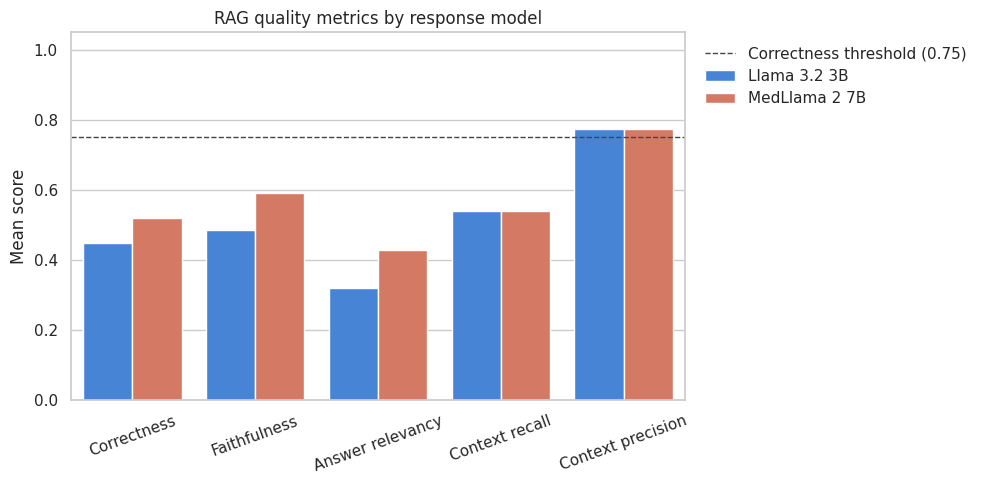

In [19]:
metric_labels = {
    "correctness_score": "Correctness",
    "faithfulness": "Faithfulness",
    "answer_relevancy": "Answer relevancy",
    "context_recall": "Context recall",
    "llm_context_precision_with_reference": "Context precision",
}

metric_summary = (
    results.melt(id_vars="model", value_vars=QUALITY_METRICS, var_name="metric", value_name="score")
    .groupby(["model", "metric"], as_index=False)["score"]
    .mean()
)
metric_summary["metric_label"] = metric_summary["metric"].map(metric_labels)

fig, ax = plt.subplots(figsize=(10, 5))
if sns:
    sns.barplot(data=metric_summary, x="metric_label", y="score", hue="model", order=list(metric_labels.values()), hue_order=MODEL_ORDER, palette=MODEL_COLORS, ax=ax)
else:
    pivot = metric_summary.pivot(index="metric_label", columns="model", values="score").loc[list(metric_labels.values()), MODEL_ORDER]
    pivot.plot(kind="bar", color=[MODEL_COLORS[m] for m in MODEL_ORDER], ax=ax)
ax.axhline(threshold, color="#444", linestyle="--", linewidth=1, label=f"Correctness threshold ({threshold:.2f})")
ax.set_ylim(0, 1.05)
ax.set_xlabel("")
ax.set_ylabel("Mean score")
ax.set_title("RAG quality metrics by response model")
ax.tick_params(axis="x", rotation=20)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()

## Correctness Distribution

Mean scores hide the practical issue: many answers cluster below the pass threshold even when the model is often partially correct.

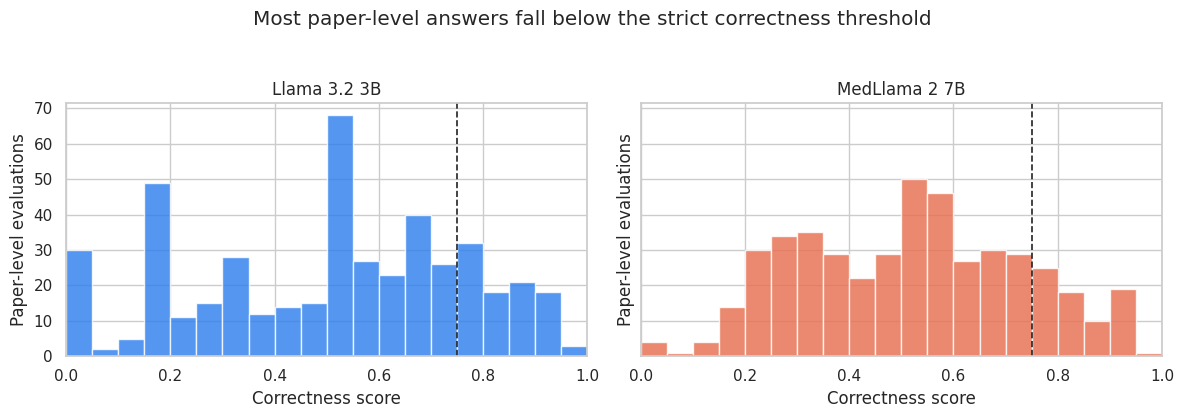

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, model in zip(axes, MODEL_ORDER):
    values = results.loc[results["model"] == model, "correctness_score"]
    ax.hist(values, bins=np.linspace(0, 1, 21), color=MODEL_COLORS[model], alpha=0.82, edgecolor="white")
    ax.axvline(threshold, color="#222", linestyle="--", linewidth=1.2)
    ax.set_title(model)
    ax.set_xlabel("Correctness score")
    ax.set_ylabel("Paper-level evaluations")
    ax.set_xlim(0, 1)
plt.suptitle("Most paper-level answers fall below the strict correctness threshold", y=1.04)
plt.tight_layout()

## Category-Level Strengths And Failure Modes

This view ranks categories by the MedLlama correctness lift over Llama. Positive values mean MedLlama did better; negative values mean Llama did better.

Largest MedLlama gains


model,Llama 3.2 3B,MedLlama 2 7B,MedLlama minus Llama
category,,,
cohort.inclusion,0.436,0.703,0.267
features.temporal,0.188,0.450,0.262
features.number,0.288,0.506,0.218
feature.temporal_resolution,0.144,0.358,0.214
outcome.classbalance,0.245,0.446,0.202
outcome.secondary,0.207,0.408,0.201
outcome.primary,0.417,0.602,0.185
evaluation.best_model,0.396,0.576,0.180


Largest MedLlama losses


model,Llama 3.2 3B,MedLlama 2 7B,MedLlama minus Llama
category,,,
cohort.clinical_domain,0.746,0.441,-0.305
processing.missing,0.851,0.657,-0.194
model.validation_strategy,0.518,0.466,-0.052
features.groups,0.669,0.631,-0.039
processing.selection,0.479,0.442,-0.037
evaluation.explainability,0.507,0.471,-0.036
evaluation.metrics_per_model,0.563,0.574,0.011
cohort.demographics,0.576,0.588,0.011


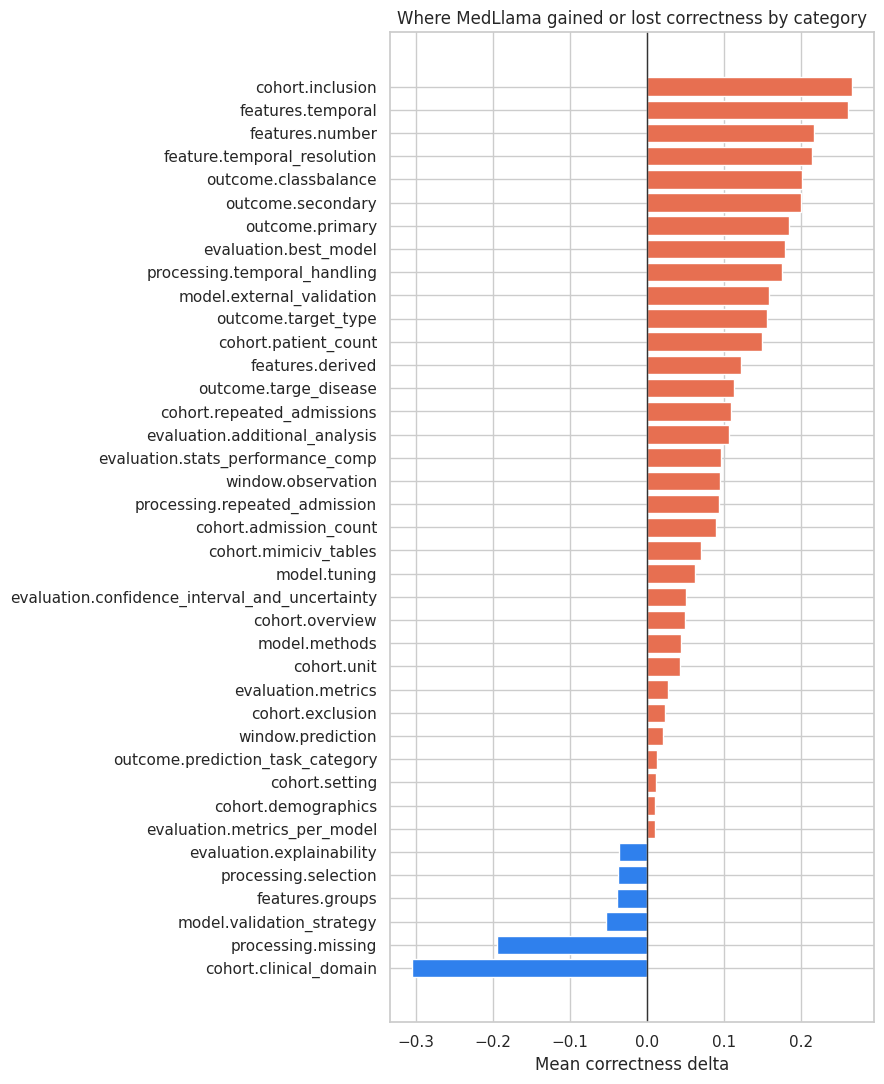

In [20]:
category_scores = (
    results.groupby(["category", "model"], as_index=False)
    .agg(
        mean_correctness=("correctness_score", "mean"),
        pass_rate=("is_correct", "mean"),
        n=("query_id", "size"),
    )
)
category_delta = category_scores.pivot(index="category", columns="model", values="mean_correctness")
category_delta["MedLlama minus Llama"] = category_delta["MedLlama 2 7B"] - category_delta["Llama 3.2 3B"]
category_delta = category_delta.sort_values("MedLlama minus Llama")

fig, ax = plt.subplots(figsize=(9, 11))
colors = np.where(category_delta["MedLlama minus Llama"] >= 0, MODEL_COLORS["MedLlama 2 7B"], MODEL_COLORS["Llama 3.2 3B"])
ax.barh(category_delta.index, category_delta["MedLlama minus Llama"], color=colors)
ax.axvline(0, color="#333", linewidth=1)
ax.set_xlabel("Mean correctness delta")
ax.set_ylabel("")
ax.set_title("Where MedLlama gained or lost correctness by category")
plt.tight_layout()

print("Largest MedLlama gains")
display(category_delta.tail(8).sort_values("MedLlama minus Llama", ascending=False).round(3))
print("Largest MedLlama losses")
display(category_delta.head(8).round(3))

## Field Group Performance

The `field_id` rollup is easier to read than the full category list and helps show whether failures concentrate in cohort extraction, feature extraction, model methods, outcomes, processing, or temporal windows.

model,Llama 3.2 3B,MedLlama 2 7B
field_id,,
cohort,0.489,0.536
evaluation,0.432,0.495
features,0.360,0.491
modelling,0.489,0.542
outcome,0.442,0.588
processing,0.461,0.470
window,0.385,0.443


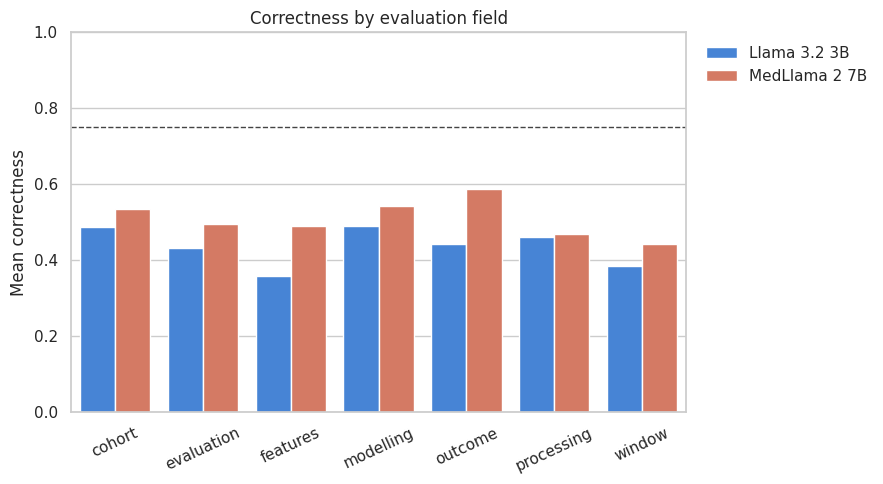

In [21]:
field_scores = (
    results.groupby(["field_id", "model"], as_index=False)
    .agg(mean_correctness=("correctness_score", "mean"), pass_rate=("is_correct", "mean"), n=("query_id", "size"))
)

fig, ax = plt.subplots(figsize=(9, 5))
if sns:
    sns.barplot(data=field_scores, x="field_id", y="mean_correctness", hue="model", hue_order=MODEL_ORDER, palette=MODEL_COLORS, ax=ax)
else:
    field_scores.pivot(index="field_id", columns="model", values="mean_correctness")[MODEL_ORDER].plot(kind="bar", color=[MODEL_COLORS[m] for m in MODEL_ORDER], ax=ax)
ax.axhline(threshold, color="#444", linestyle="--", linewidth=1)
ax.set_ylim(0, 1.0)
ax.set_xlabel("")
ax.set_ylabel("Mean correctness")
ax.set_title("Correctness by evaluation field")
ax.tick_params(axis="x", rotation=25)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()

display(field_scores.pivot(index="field_id", columns="model", values="mean_correctness").reindex(columns=MODEL_ORDER).round(3))

## Retrieval Diagnostics

Both CSVs show the response included the expected paper for every row, and the context recall/precision means are identical across models. That suggests the larger bottleneck is not selecting the paper, but extracting and composing the exact answer from retrieved context.

,retrieved_context_count,expected_context_count,context_recall,llm_context_precision_with_reference,matched_response_paper,missing_paper_count,extra_paper_count
model,,,,,,,
Llama 3.2 3B,1.083,1.000,0.541,0.775,1.000,0.000,0.024
MedLlama 2 7B,1.083,1.000,0.541,0.775,1.000,0.000,0.024


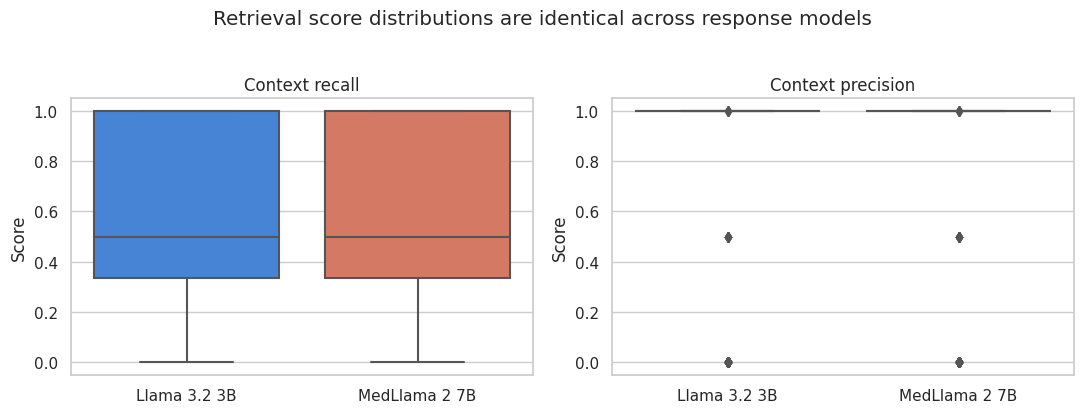

In [22]:
retrieval_cols = [
    "retrieved_context_count",
    "expected_context_count",
    "context_recall",
    "llm_context_precision_with_reference",
    "matched_response_paper",
    "missing_paper_count",
    "extra_paper_count",
]
retrieval_summary = results.groupby("model")[retrieval_cols].mean().reindex(MODEL_ORDER)
display(retrieval_summary.style.format("{:.3f}"))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ["context_recall", "llm_context_precision_with_reference"]):
    plot_df = results[["model", metric]].copy()
    if sns:
        sns.boxplot(data=plot_df, x="model", y=metric, order=MODEL_ORDER, palette=MODEL_COLORS, ax=ax)
    else:
        plot_df.boxplot(column=metric, by="model", ax=ax)
    ax.set_title(metric_labels.get(metric, metric))
    ax.set_xlabel("")
    ax.set_ylabel("Score")
    ax.set_ylim(-0.05, 1.05)
plt.suptitle("Retrieval score distributions are identical across response models", y=1.03)
plt.tight_layout()

## Latency Trade-Off

This chart shows the quality/speed trade-off. MedLlama improves average correctness, but it costs substantially more generation time in this run.

,model,mean_correctness,median_latency_seconds,mean_latency_seconds,pass_rate
0,Llama 3.2 3B,0.449,52.050,61.634,0.074
1,MedLlama 2 7B,0.521,127.562,134.115,0.048


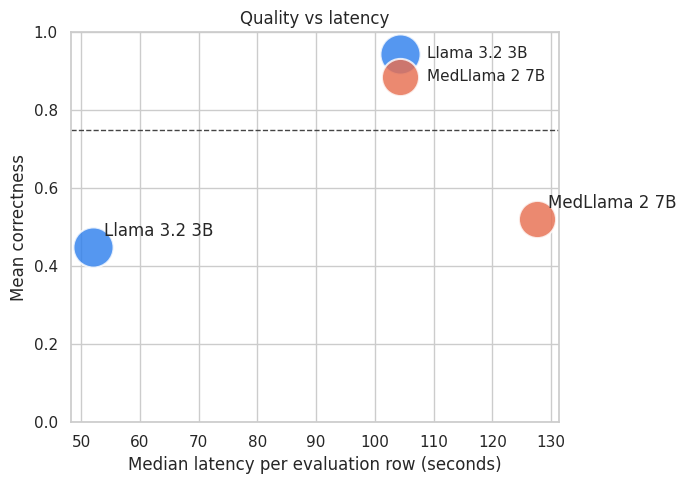

In [23]:
latency_quality = (
    results.groupby("model", as_index=False)
    .agg(
        mean_correctness=("correctness_score", "mean"),
        median_latency_seconds=("api_latency_seconds", "median"),
        mean_latency_seconds=("api_latency_seconds", "mean"),
        pass_rate=("is_correct", "mean"),
    )
)

fig, ax = plt.subplots(figsize=(7, 5))
for _, row in latency_quality.iterrows():
    ax.scatter(
        row["median_latency_seconds"],
        row["mean_correctness"],
        s=500 + row["pass_rate"] * 4500,
        color=MODEL_COLORS[row["model"]],
        alpha=0.82,
        edgecolor="white",
        linewidth=1.5,
        label=row["model"],
    )
    ax.annotate(row["model"], (row["median_latency_seconds"], row["mean_correctness"]), xytext=(8, 8), textcoords="offset points")
ax.axhline(threshold, color="#444", linestyle="--", linewidth=1)
ax.set_xlabel("Median latency per evaluation row (seconds)")
ax.set_ylabel("Mean correctness")
ax.set_title("Quality vs latency")
ax.set_ylim(0, 1)
ax.legend(frameon=False)
plt.tight_layout()

display(latency_quality.round(3))

## Paper-Level Hotspots

These tables identify papers where both models struggled and papers where one response model clearly outperformed the other. Use these rows for qualitative error review against `response`, `reference`, and `retrieved_contexts`.

In [24]:
paper_scores = (
    results.groupby(["article_id", "article_title", "model"], as_index=False)
    .agg(
        mean_correctness=("correctness_score", "mean"),
        pass_rate=("is_correct", "mean"),
        mean_faithfulness=("faithfulness", "mean"),
        mean_answer_relevancy=("answer_relevancy", "mean"),
        rows=("query_id", "size"),
    )
)
paper_pivot = paper_scores.pivot_table(
    index=["article_id", "article_title"],
    columns="model",
    values="mean_correctness",
)
paper_pivot["average"] = paper_pivot[MODEL_ORDER].mean(axis=1)
paper_pivot["delta_medllama_minus_llama"] = paper_pivot["MedLlama 2 7B"] - paper_pivot["Llama 3.2 3B"]

print("Lowest average correctness across both models")
display(paper_pivot.sort_values("average").head(10).round(3))

print("Largest model disagreements")
display(paper_pivot.reindex(paper_pivot["delta_medllama_minus_llama"].abs().sort_values(ascending=False).index).head(15).round(3))

Lowest average correctness across both models


,model,Llama 3.2 3B,MedLlama 2 7B,average,delta_medllama_minus_llama
article_id,article_title,,,,
s12871-023-02138-5,Prediction model of in-hospital mortality in intensive care unit patients with cardiac arrest: a retrospective analysis of MIMIC -IV database based on machine learning - BMC Anesthesiology,0.367,0.470,0.418,0.103
s41467-025-62527-x,The HM-TARGET personalised real-time haemodynamic targets in critical care - Nature Communications,0.362,0.489,0.425,0.128
s12933-023-02041-w,Association between triglyceride-glucose index and in-hospital mortality in critically ill patients with sepsis: analysis of the MIMIC-IV database - Cardiovascular Diabetology,0.376,0.520,0.448,0.144
s12873-022-00582-z,Prediction of prognosis in elderly patients with sepsis...,0.427,0.490,0.459,0.063
s12872-025-04628-5,Comparison of machine learning and nomogram to predict 30-day in-hospital mortality in patients with acute myocardial infarction combined with cardiogenic shock: a retrospective study based on the eICU-CRD and MIMIC-IV databases - BMC Cardiovascular Disorders,0.447,0.489,0.468,0.043
s12933-024-02265-4,Association between the stress hyperglycemia ratio and 28-day all-cause mortality in critically ill patients with sepsis: a retrospective cohort study and predictive model establishment based on machine learning - Cardiovascular Diabetology,0.453,0.487,0.470,0.034
s41598-025-93516-1,Development and validation of machine learning models for predicting extubation failure in patients undergoing cardiac surgery: a retrospective study - Scientific Reports,0.439,0.535,0.487,0.096
s12873-022-00582-z,Factors and machine learning models for predicting successful discontinuation of continuous renal replacement therapy in critically ill patients with acute kidney injury: a retrospective cohort study based on MIMIC-IV database,0.480,0.529,0.505,0.049
s40001-025-02622-3,Explainable machine learning model for prediction of 28-day all-cause mortality in immunocompromised patients in the intensive care unit: a retrospective cohort study based on MIMIC-IV database - European Journal of Medical Research,0.504,0.516,0.510,0.012


Largest model disagreements


model                                                                  Llama 3.2 3B  \
article_id         article_title                                                      
s12933-023-02041-w Association between triglyceride-glucose index ...         0.376   
s41467-025-62527-x The HM-TARGET personalised real-time haemodynam...         0.362   
s12871-023-02138-5 Prediction model of in-hospital mortality in in...         0.367   
s41598-025-93516-1 Development and validation of machine learning ...         0.439   
s12893-023-02151-y Construction and validation of machine learning...         0.526   
s12872-026-05943-1 Early prediction of in-hospital mortality in IC...         0.510   
s12873-022-00582-z Prediction of prognosis in elderly patients wit...         0.427   
                   Factors and machine learning models for predict...         0.480   
s40001-023-01593-7 Interpretable machine learning model for early ...         0.494   
s12872-025-04628-5 Comparison of machine learning and nomogram to ...         0.447   
s12933-024-02265-4 Association between the stress hyperglycemia ra...         0.453   
s40001-025-02622-3 Explainable machine learning model for predicti...         0.504   

model                                                                  MedLlama 2 7B  \
article_id         article_title                                                       
s12933-023-02041-w Association between triglyceride-glucose index ...          0.520   
s41467-025-62527-x The HM-TARGET personalised real-time haemodynam...          0.489   
s12871-023-02138-5 Prediction model of in-hospital mortality in in...          0.470   
s41598-025-93516-1 Development and validation of machine learning ...          0.535   
s12893-023-02151-y Construction and validation of machine learning...          0.609   
s12872-026-05943-1 Early prediction of in-hospital mortality in IC...          0.574   
s12873-022-00582-z Prediction of prognosis in elderly patients wit...          0.490   
                   Factors and machine learning models for predict...          0.529   
s40001-023-01593-7 Interpretable machine learning model for early ...          0.539   
s12872-025-04628-5 Comparison of machine learning and nomogram to ...          0.489   
s12933-024-02265-4 Association between the stress hyperglycemia ra...          0.487   
s40001-025-02622-3 Explainable machine learning model for predicti...          0.516   

model                                                                  average  \
article_id         article_title                                                 
s12933-023-02041-w Association between triglyceride-glucose index ...    0.448   
s41467-025-62527-x The HM-TARGET personalised real-time haemodynam...    0.425   
s12871-023-02138-5 Prediction model of in-hospital mortality in in...    0.418   
s41598-025-93516-1 Development and validation of machine learning ...    0.487   
s12893-023-02151-y Construction and validation of machine learning...    0.567   
s12872-026-05943-1 Early prediction of in-hospital mortality in IC...    0.542   
s12873-022-00582-z Prediction of prognosis in elderly patients wit...    0.459   
                   Factors and machine learning models for predict...    0.505   
s40001-023-01593-7 Interpretable machine learning model for early ...    0.517   
s12872-025-04628-5 Comparison of machine learning and nomogram to ...    0.468   
s12933-024-02265-4 Association between the stress hyperglycemia ra...    0.470   
s40001-025-02622-3 Explainable machine learning model for predicti...    0.510   

model                                                                  delta_medllama_minus_llama  
article_id         article_title                                                                   
s12933-023-02041-w Association between triglyceride-glucose index ...                       0.144  
s41467-025-62527-x The HM-TARGET personalised real-time haemodynam...                       0.128  

## Query Difficulty

Every query outcome is `Needs review`, so the useful view is not the outcome label; it is the query/category mean score. The lowest-scoring queries are likely where prompt wording, expected references, or retrieval chunking need attention.

Hardest queries by average correctness


,,model,Llama 3.2 3B,MedLlama 2 7B,average,delta_medllama_minus_llama
query_id,category,field_id,,,,
22,feature.temporal_resolution,features,0.144,0.358,0.251,0.214
3,cohort.mimiciv_tables,cohort,0.253,0.324,0.289,0.071
14,outcome.secondary,outcome,0.207,0.408,0.307,0.201
24,features.temporal,features,0.188,0.450,0.319,0.262
26,processing.repeated_admission,processing,0.273,0.367,0.320,0.094
27,processing.temporal_handling,processing,0.240,0.415,0.328,0.175
17,outcome.classbalance,outcome,0.245,0.446,0.346,0.202
6,cohort.repeated_admissions,cohort,0.292,0.402,0.347,0.109
39,evaluation.additional_analysis,evaluation,0.302,0.409,0.355,0.107


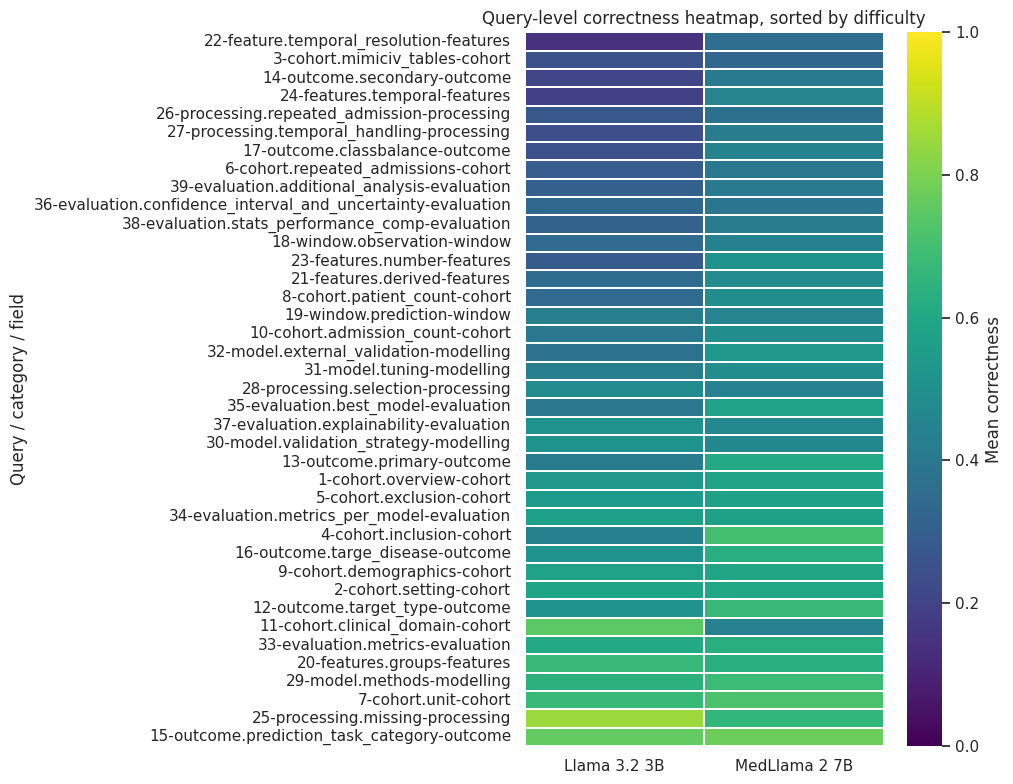

In [25]:
query_scores = (
    results.groupby(["query_id", "category", "field_id", "model"], as_index=False)
    .agg(
        mean_correctness=("correctness_score", "mean"),
        pass_rate=("is_correct", "mean"),
        mean_context_recall=("context_recall", "mean"),
        mean_context_precision=("llm_context_precision_with_reference", "mean"),
    )
)
query_pivot = query_scores.pivot_table(
    index=["query_id", "category", "field_id"],
    columns="model",
    values="mean_correctness",
)
query_pivot["average"] = query_pivot[MODEL_ORDER].mean(axis=1)
query_pivot["delta_medllama_minus_llama"] = query_pivot["MedLlama 2 7B"] - query_pivot["Llama 3.2 3B"]

print("Hardest queries by average correctness")
display(query_pivot.sort_values("average").head(12).round(3))

fig, ax = plt.subplots(figsize=(10, 8))
heatmap_data = query_pivot.sort_values("average")[MODEL_ORDER]
if sns:
    sns.heatmap(heatmap_data, cmap="viridis", vmin=0, vmax=1, linewidths=0.2, cbar_kws={"label": "Mean correctness"}, ax=ax)
else:
    im = ax.imshow(heatmap_data.values, aspect="auto", vmin=0, vmax=1, cmap="viridis")
    ax.set_xticks(range(len(MODEL_ORDER)), MODEL_ORDER)
    ax.set_yticks(range(len(heatmap_data.index)), [str(i) for i in heatmap_data.index])
    fig.colorbar(im, ax=ax, label="Mean correctness")
ax.set_title("Query-level correctness heatmap, sorted by difficulty")
ax.set_xlabel("")
ax.set_ylabel("Query / category / field")
plt.tight_layout()

## Inspect Individual Failures

Change the filters below to inspect representative failed rows. The compact preview includes the model response, reference answer, and retrieved context so you can quickly classify error types such as missing inclusion criteria, wrong temporal window, over-generalization, or unsupported clinical assumptions.

In [26]:
def preview_failure(category=None, model=None, min_context_recall=None, max_rows=5):
    subset = results.copy()
    if category is not None:
        subset = subset[subset["category"].eq(category)]
    if model is not None:
        subset = subset[subset["model"].eq(model)]
    if min_context_recall is not None:
        subset = subset[subset["context_recall"].ge(min_context_recall)]

    cols = [
        "model", "query_id", "category", "article_title", "correctness_score",
        "faithfulness", "answer_relevancy", "context_recall", "response", "reference", "retrieved_contexts",
    ]
    subset = subset.sort_values(["correctness_score", "context_recall"], ascending=[True, False]).head(max_rows)

    for _, row in subset[cols].iterrows():
        print("=" * 110)
        print(f"{row['model']} | query {row['query_id']} | {row['category']} | correctness={row['correctness_score']:.3f} | recall={row['context_recall']:.3f}")
        print(textwrap.shorten(row["article_title"], width=130, placeholder="..."))
        print("\nResponse")
        print(textwrap.shorten(str(row["response"]).replace("<br>", " "), width=700, placeholder="..."))
        print("\nReference")
        print(textwrap.shorten(str(row["reference"]), width=700, placeholder="..."))
        print("\nRetrieved context preview")
        print(textwrap.shorten(str(row["retrieved_contexts"]), width=900, placeholder="..."))

preview_failure(max_rows=3)

Llama 3.2 3B | query 3 | cohort.mimiciv_tables | correctness=0.000 | recall=0.000
Association between triglyceride-glucose index and in-hospital mortality in critically ill patients with sepsis: analysis of...

Response
Not found in this paper.

Reference
The authors report of using MIMIC-IV v2.2 and SQL extraction but do not name the individual tables.

Retrieved context preview
['ARTICLE ID: s12933-023-02041-w\nTITLE: Association between triglyceride-glucose index and in-hospital mortality in critically ill patients with sepsis: analysis of the MIMIC-IV database - Cardiovascular Diabetology\nSECTIONS: abstract, methods\n\nTitle: Association between triglyceride-glucose index and in-hospital mortality in critically ill patients with sepsis: analysis of the MIMIC-IV database - Cardiovascular Diabetology\nSection: abstract\n\nContent:\nThis study aimed to explore the association between the triglyceride-glucose (TyG) index and the risk of in-hospital mortality in critically ill patients

## Interpretation Notes

- MedLlama is the stronger answer generator in this run: higher mean correctness, faithfulness, and answer relevancy.
- The improvement is not enough for reliable automation under the current threshold; most rows still require review.
- Retrieval paper matching is perfect in these files, and retrieval recall/precision are identical, so the next quality gains likely come from answer prompting, evidence formatting, chunk selection within the matched paper, or post-generation verification.
- Low scores cluster in detail-heavy categories such as temporal resolution, patient counts, class balance, repeated admissions, and secondary outcomes. These usually require exact extraction rather than broad summarization.
- Llama 3.2 3B is much faster. If throughput matters, it may still be useful for coarse triage, but MedLlama is preferable where answer quality matters more than latency.


# Judge-Robust RAG Weakness Analysis

This section compares the same RAG outputs judged by `qwen2.5:7b` and `gpt-5.6-luna`. The goal is not to choose the best response model, but to find query categories where the RAG pipeline is reliably strong or weak across judges.

Use the judge-robust averages as the main signal. Use judge disagreement as a caution flag: when judges disagree strongly, avoid over-interpreting model/category deltas without manual review.


In [27]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    import seaborn as sns
    sns.set_theme(style="whitegrid", context="notebook")
except ImportError:
    sns = None
    plt.style.use("seaborn-v0_8-whitegrid")

JUDGE_COMPARISON_FILES = {
    ("Llama", "Qwen 2.5 7B"): Path("results_v3/llama_3_2_3b__qwen2_5_7b.csv"),
    ("MedLlama", "Qwen 2.5 7B"): Path("results_v3/medllama_2_7b__qwen2_5_7b.csv"),
    ("Llama", "GPT-5.6 Luna"): Path("results_v4/llama_3_2b__gpt_5_6_luna.csv"),
    ("MedLlama", "GPT-5.6 Luna"): Path("results_v4/medllama_2_7b__gpt_5_6_luna.csv"),
}

frames = []
for (response_model, judge_model), file_path in JUDGE_COMPARISON_FILES.items():
    df = pd.read_csv(file_path)
    df["response_family"] = response_model
    df["judge_family"] = judge_model
    df["run_label"] = f"{response_model} judged by {judge_model}"
    frames.append(df)

judge_results = pd.concat(frames, ignore_index=True)
judge_results["is_correct"] = judge_results["is_correct"].astype(bool)
judge_results.head()

,query_id,eval_unit,paper_index,article_id,article_title,reference_section,reference_status,source_row,api_latency_seconds,retrieved_context_count,...,paper_accuracy,min_paper_correctness,all_papers_correct,query_outcome,response_model,judge_model,embedding_model,response_family,judge_family,run_label
0,1,paper,1,s12873-022-00582-z,Prediction of prognosis in elderly patients wi...,Methods,reported,2,91.713876,1,...,0.083333,0.111111,False,Needs review,llama3.2:3b,qwen2.5:7b,nomic-embed-text:latest,Llama,Qwen 2.5 7B,Llama judged by Qwen 2.5 7B
1,1,paper,2,s12933-023-02041-w,Association between triglyceride-glucose index...,Methods,reported,41,91.713876,1,...,0.083333,0.111111,False,Needs review,llama3.2:3b,qwen2.5:7b,nomic-embed-text:latest,Llama,Qwen 2.5 7B,Llama judged by Qwen 2.5 7B
2,1,paper,3,s12873-022-00582-z,Factors and machine learning models for predic...,"Abstract, Methods",reported,80,91.713876,2,...,0.083333,0.111111,False,Needs review,llama3.2:3b,qwen2.5:7b,nomic-embed-text:latest,Llama,Qwen 2.5 7B,Llama judged by Qwen 2.5 7B
3,1,paper,4,s12933-024-02265-4,Association between the stress hyperglycemia r...,Methods,reported,119,91.713876,1,...,0.083333,0.111111,False,Needs review,llama3.2:3b,qwen2.5:7b,nomic-embed-text:latest,Llama,Qwen 2.5 7B,Llama judged by Qwen 2.5 7B
4,1,paper,5,s40001-023-01593-7,Interpretable machine learning model for early...,Methods,reported,158,91.713876,1,...,0.083333,0.111111,False,Needs review,llama3.2:3b,qwen2.5:7b,nomic-embed-text:latest,Llama,Qwen 2.5 7B,Llama judged by Qwen 2.5 7B


## Judge-Robust Category Ranking

This ranks categories by average correctness across both response models and both judges. Categories at the bottom are the most reliable RAG weaknesses because they stay weak even when the judge changes.

Most difficult categories across both judges and both models


,category,mean_correctness,median_correctness,pass_rate,mean_context_recall,mean_context_precision,n
18,feature.temporal_resolution,0.288,0.244,0.000,0.195,0.250,48
30,outcome.secondary,0.314,0.258,0.000,0.333,0.667,48
22,features.temporal,0.330,0.319,0.000,0.000,1.000,4
11,evaluation.additional_analysis,0.349,0.344,0.000,0.388,0.687,48
5,cohort.mimiciv_tables,0.349,0.342,0.000,0.507,0.854,48
27,outcome.classbalance,0.372,0.350,0.000,0.441,0.583,48
21,features.number,0.379,0.320,0.000,0.410,0.437,48
37,window.observation,0.383,0.333,0.000,0.310,0.417,48
38,window.prediction,0.389,0.334,0.000,0.295,0.667,48
34,processing.repeated_admission,0.393,0.375,0.021,0.646,0.729,48


Best answered categories across both judges and both models


,category,mean_correctness,median_correctness,pass_rate,mean_context_recall,mean_context_precision,n
33,processing.missing,0.787,0.825,0.417,0.823,1.000,48
28,outcome.prediction_task_category,0.743,0.836,0.167,0.670,0.958,48
15,evaluation.metrics,0.633,0.680,0.000,0.425,0.917,48
1,cohort.clinical_domain,0.633,0.609,0.167,0.694,1.000,48
10,cohort.unit,0.629,0.667,0.062,0.625,1.000,48
24,model.methods,0.611,0.643,0.021,0.443,0.792,48
9,cohort.setting,0.606,0.671,0.000,0.642,0.979,48
3,cohort.exclusion,0.601,0.716,0.125,0.570,0.750,48
20,features.groups,0.598,0.612,0.021,0.376,0.958,48
31,outcome.targe_disease,0.566,0.610,0.000,0.615,0.958,48


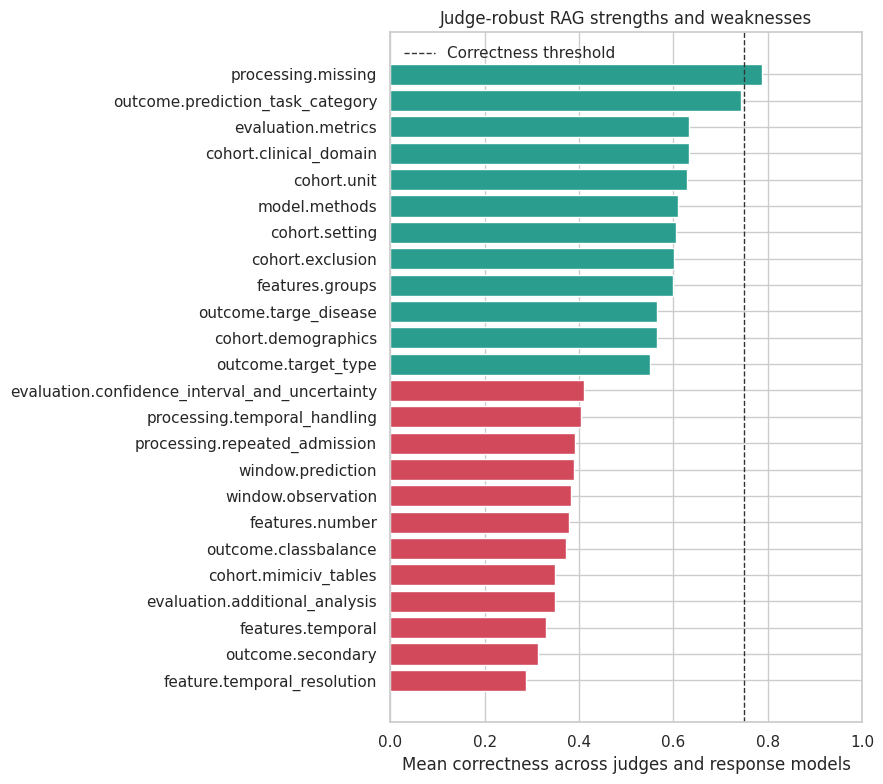

In [28]:
robust_category = (
    judge_results.groupby("category", as_index=False)
    .agg(
        mean_correctness=("correctness_score", "mean"),
        median_correctness=("correctness_score", "median"),
        pass_rate=("is_correct", "mean"),
        mean_context_recall=("context_recall", "mean"),
        mean_context_precision=("llm_context_precision_with_reference", "mean"),
        n=("correctness_score", "size"),
    )
    .sort_values("mean_correctness")
)

print("Most difficult categories across both judges and both models")
display(robust_category.head(12).round(3))

print("Best answered categories across both judges and both models")
display(robust_category.tail(12).sort_values("mean_correctness", ascending=False).round(3))

plot_df = pd.concat([
    robust_category.head(12).assign(group="Weakest"),
    robust_category.tail(12).assign(group="Strongest"),
])
plot_df = plot_df.sort_values("mean_correctness")

fig, ax = plt.subplots(figsize=(9, 8))
colors = np.where(plot_df["group"].eq("Strongest"), "#2a9d8f", "#d1495b")
ax.barh(plot_df["category"], plot_df["mean_correctness"], color=colors)
ax.axvline(0.75, color="#333", linestyle="--", linewidth=1, label="Correctness threshold")
ax.set_xlabel("Mean correctness across judges and response models")
ax.set_ylabel("")
ax.set_xlim(0, 1)
ax.set_title("Judge-robust RAG strengths and weaknesses")
ax.legend(frameon=False)
plt.tight_layout()

## Field-Level Weakness

This compresses categories into broader extraction fields. It shows whether the RAG system struggles more with cohort, features, outcomes, processing, modelling, or time-window questions.

,field_id,mean_correctness,pass_rate,mean_context_recall,mean_context_precision,n
6,window,0.386,0.000,0.302,0.542,96
2,features,0.427,0.005,0.319,0.607,196
1,evaluation,0.482,0.039,0.382,0.741,336
4,outcome,0.512,0.045,0.519,0.802,288
5,processing,0.514,0.130,0.533,0.802,192
0,cohort,0.531,0.070,0.558,0.807,528
3,modelling,0.532,0.052,0.525,0.849,192


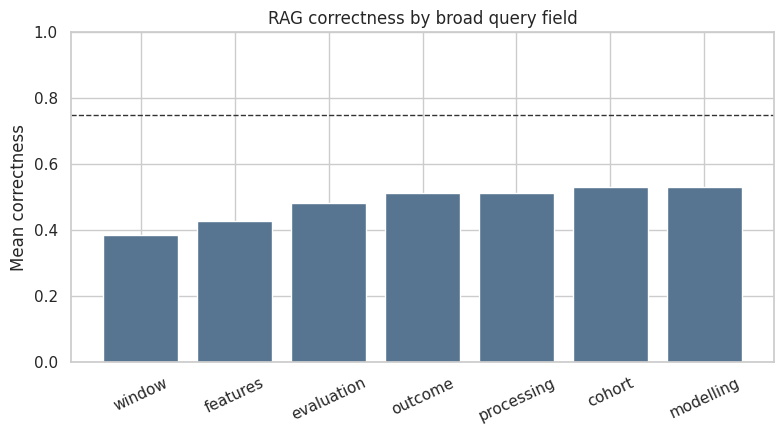

In [29]:
field_summary = (
    judge_results.groupby("field_id", as_index=False)
    .agg(
        mean_correctness=("correctness_score", "mean"),
        pass_rate=("is_correct", "mean"),
        mean_context_recall=("context_recall", "mean"),
        mean_context_precision=("llm_context_precision_with_reference", "mean"),
        n=("correctness_score", "size"),
    )
    .sort_values("mean_correctness")
)

display(field_summary.round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(field_summary["field_id"], field_summary["mean_correctness"], color="#577590")
ax.axhline(0.75, color="#333", linestyle="--", linewidth=1)
ax.set_ylim(0, 1)
ax.set_xlabel("")
ax.set_ylabel("Mean correctness")
ax.set_title("RAG correctness by broad query field")
ax.tick_params(axis="x", rotation=25)
plt.tight_layout()

## Judge Disagreement

These categories should be treated carefully. A large judge delta means conclusions depend heavily on whether Qwen or GPT-Luna is judging. Stable hard/easy categories are more useful for diagnosing RAG behavior.

Categories with largest judge disagreement


judge_family,GPT-5.6 Luna,Qwen 2.5 7B,GPT-Luna minus Qwen,absolute_judge_delta
category,,,,
cohort.repeated_admissions,0.594,0.347,0.247,0.247
evaluation.stats_performance_comp,0.588,0.363,0.225,0.225
processing.temporal_handling,0.479,0.328,0.152,0.152
processing.repeated_admission,0.465,0.320,0.146,0.146
cohort.inclusion,0.436,0.570,-0.134,0.134
cohort.unit,0.563,0.695,-0.133,0.133
cohort.mimiciv_tables,0.410,0.289,0.121,0.121
cohort.admission_count,0.562,0.444,0.119,0.119
model.tuning,0.566,0.458,0.108,0.108


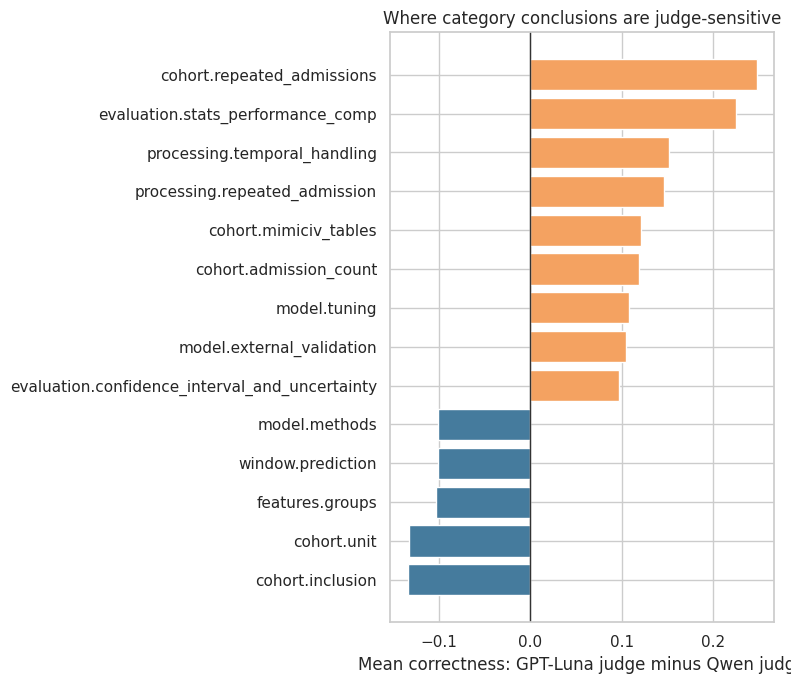

In [30]:
judge_category = (
    judge_results.groupby(["category", "judge_family"], as_index=False)["correctness_score"]
    .mean()
    .pivot(index="category", columns="judge_family", values="correctness_score")
)
judge_category["GPT-Luna minus Qwen"] = judge_category["GPT-5.6 Luna"] - judge_category["Qwen 2.5 7B"]
judge_category["absolute_judge_delta"] = judge_category["GPT-Luna minus Qwen"].abs()
judge_category = judge_category.sort_values("absolute_judge_delta", ascending=False)

print("Categories with largest judge disagreement")
display(judge_category.head(12).round(3))

fig, ax = plt.subplots(figsize=(8, 7))
top_disagreement = judge_category.head(14).sort_values("GPT-Luna minus Qwen")
colors = np.where(top_disagreement["GPT-Luna minus Qwen"] >= 0, "#f4a261", "#457b9d")
ax.barh(top_disagreement.index, top_disagreement["GPT-Luna minus Qwen"], color=colors)
ax.axvline(0, color="#333", linewidth=1)
ax.set_xlabel("Mean correctness: GPT-Luna judge minus Qwen judge")
ax.set_ylabel("")
ax.set_title("Where category conclusions are judge-sensitive")
plt.tight_layout()

## Stable Strengths And Stable Weaknesses

This filters for categories that both judges agree are weak or strong. These are better candidates for thesis-level claims than model-vs-model deltas.

In [31]:
stable_weak = (
    judge_category[(judge_category["GPT-5.6 Luna"] < 0.40) & (judge_category["Qwen 2.5 7B"] < 0.40)]
    .sort_values(["GPT-5.6 Luna", "Qwen 2.5 7B"])
)
stable_strong = (
    judge_category[(judge_category["GPT-5.6 Luna"] > 0.60) & (judge_category["Qwen 2.5 7B"] > 0.60)]
    .sort_values(["GPT-5.6 Luna", "Qwen 2.5 7B"], ascending=False)
)

print("Stable weaknesses: both judges score below 0.40")
display(stable_weak.round(3))

print("Stable strengths: both judges score above 0.60")
display(stable_strong.round(3))

Stable weaknesses: both judges score below 0.40


judge_family,GPT-5.6 Luna,Qwen 2.5 7B,GPT-Luna minus Qwen,absolute_judge_delta
category,,,,
outcome.secondary,0.321,0.307,0.013,0.013
feature.temporal_resolution,0.326,0.251,0.075,0.075
features.temporal,0.340,0.319,0.020,0.020
evaluation.additional_analysis,0.342,0.355,-0.014,0.014
features.number,0.362,0.397,-0.035,0.035
window.observation,0.379,0.388,-0.010,0.010
outcome.classbalance,0.398,0.346,0.053,0.053


Stable strengths: both judges score above 0.60


judge_family,GPT-5.6 Luna,Qwen 2.5 7B,GPT-Luna minus Qwen,absolute_judge_delta
category,,,,
processing.missing,0.821,0.754,0.067,0.067
outcome.prediction_task_category,0.719,0.767,-0.048,0.048
evaluation.metrics,0.648,0.619,0.030,0.030


## Retrieval Versus Answering Failure

Low correctness with low context recall suggests retrieval/chunking weakness. Low correctness with high context precision but modest recall often means the system retrieved relevant material but missed specific details during answer extraction.

Lowest-correctness categories with likely failure mode


,category,mean_correctness,mean_context_recall,mean_context_precision,likely_failure_mode,n
18,feature.temporal_resolution,0.288,0.195,0.250,retrieval/chunk recall,48
30,outcome.secondary,0.314,0.333,0.667,retrieval/chunk recall,48
22,features.temporal,0.330,0.000,1.000,retrieval/chunk recall,4
11,evaluation.additional_analysis,0.349,0.388,0.687,mixed,48
5,cohort.mimiciv_tables,0.349,0.507,0.854,answer extraction/composition,48
27,outcome.classbalance,0.372,0.441,0.583,mixed,48
21,features.number,0.379,0.410,0.437,context ranking/noise,48
37,window.observation,0.383,0.310,0.417,retrieval/chunk recall,48
38,window.prediction,0.389,0.295,0.667,retrieval/chunk recall,48
34,processing.repeated_admission,0.393,0.646,0.729,mixed,48


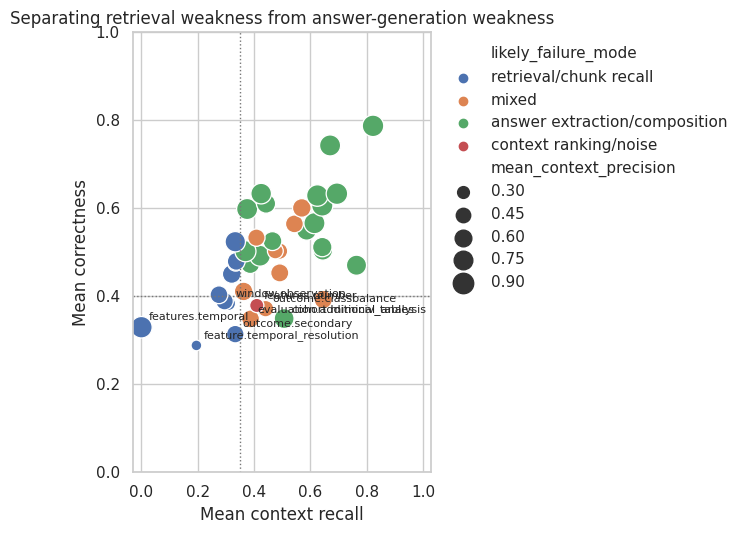

In [39]:
failure_diagnostics = robust_category.copy()
failure_diagnostics["likely_failure_mode"] = np.select(
    [
        failure_diagnostics["mean_context_recall"] < 0.35,
        (failure_diagnostics["mean_context_recall"] >= 0.35) & (failure_diagnostics["mean_context_precision"] >= 0.75),
        failure_diagnostics["mean_context_precision"] < 0.50,
    ],
    [
        "retrieval/chunk recall",
        "answer extraction/composition",
        "context ranking/noise",
    ],
    default="mixed",
)

print("Lowest-correctness categories with likely failure mode")
display(
    failure_diagnostics[
        ["category", "mean_correctness", "mean_context_recall", "mean_context_precision", "likely_failure_mode", "n"]
    ]
    .head(16)
    .round(3)
)

fig, ax = plt.subplots(figsize=(7, 5.5))
if sns:
    sns.scatterplot(
        data=failure_diagnostics,
        x="mean_context_recall",
        y="mean_correctness",
        hue="likely_failure_mode",
        size="mean_context_precision",
        sizes=(60, 240),
        ax=ax,
    )
else:
    ax.scatter(
        failure_diagnostics["mean_context_recall"],
        failure_diagnostics["mean_correctness"],
        s=120,
        alpha=0.75,
    )
for _, row in failure_diagnostics.head(8).iterrows():
    ax.annotate(row["category"], (row["mean_context_recall"], row["mean_correctness"]), xytext=(5, 5), textcoords="offset points", fontsize=8)
ax.axhline(0.40, color="#777", linestyle=":", linewidth=1)
ax.axvline(0.35, color="#777", linestyle=":", linewidth=1)
ax.set_xlim(-0.03, 1.03)
ax.set_ylim(0, 1)
ax.set_xlabel("Mean context recall")
ax.set_ylabel("Mean correctness")
ax.set_title("Separating retrieval weakness from answer-generation weakness")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()

## Takeaway

Do not use category-level model deltas as the main diagnostic when judges disagree. For RAG weakness, prioritize categories that are consistently low across judges and response models. In these runs, the most robust weak spots are temporal resolution, temporal features, secondary outcomes, class balance, observation/prediction windows, numeric feature counts, MIMIC-IV table details, and extra/additional analysis questions. The strongest categories are missing-data processing, prediction-task category, reported evaluation metrics, clinical domain, cohort unit/setting, and model-method summaries.


# Where Query Categories Live In The Papers

This section uses the `section` annotations in `datasets/ML4EHR.csv` to identify where each query category is usually answered across the 12 papers. This is a RAG design finding: categories that mostly live in Methods, Results, Abstract/Title, tables, or `Not Reported` should be routed and prompted differently.


In [33]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SECTION_DATASET = Path("datasets/ML4EHR.csv")
section_df = pd.read_csv(SECTION_DATASET, encoding="utf-8-sig")
section_df = section_df.loc[:, [c for c in section_df.columns if not str(c).startswith("Unnamed")]]
section_df = section_df.dropna(how="all")

for col in ["article_id", "article_title", "field_id", "category"]:
    if col in section_df.columns:
        section_df[col] = section_df[col].ffill()

section_df = section_df[section_df["category"].notna() & section_df["section"].notna()].copy()

SECTION_CANONICAL_ORDER = [
    "Title", "Abstract", "Methods", "Results", "Tables", "Discussion", "Supplementary", "Not Reported", "Other"
]

def normalize_section_families(value):
    text = str(value).strip()
    if not text or text.lower() in {"nan", "not reported", "not specified"}:
        return ["Not Reported"]

    normalized = text.lower().replace("methodology", "methods").replace("reults", "results")
    parts = re.split(r"\s*(?:,|/|;|\+|and)\s*", normalized)
    families = []
    for part in parts:
        part = part.strip(" .")
        if not part:
            continue
        if "not reported" in part:
            families.append("Not Reported")
        elif "table" in part:
            families.append("Tables")
        elif "title" in part:
            families.append("Title")
        elif "abstract" in part:
            families.append("Abstract")
        elif "method" in part:
            families.append("Methods")
        elif "result" in part:
            families.append("Results")
        elif "discussion" in part:
            families.append("Discussion")
        elif "supplement" in part:
            families.append("Supplementary")
        else:
            families.append("Other")
    return list(dict.fromkeys(families)) or ["Other"]

section_rows = []
for _, row in section_df.iterrows():
    families = normalize_section_families(row["section"])
    for family in families:
        section_rows.append({
            "article_id": row.get("article_id"),
            "article_title": row.get("article_title"),
            "field_id": row.get("field_id"),
            "category": row.get("category"),
            "original_section": row.get("section"),
            "section_family": family,
        })

category_sections_long = pd.DataFrame(section_rows)
category_sections_long.head()

,article_id,article_title,field_id,category,original_section,section_family
0,s12873-022-00582-z,Prediction of prognosis in elderly patients wi...,cohort,cohort.overview,Methods,Methods
1,s12873-022-00582-z,Prediction of prognosis in elderly patients wi...,cohort,cohort.setting,Methods,Methods
2,s12873-022-00582-z,Prediction of prognosis in elderly patients wi...,cohort,cohort.mimiciv_tables,Methods,Methods
3,s12873-022-00582-z,Prediction of prognosis in elderly patients wi...,cohort,cohort.inclusion,Methods,Methods
4,s12873-022-00582-z,Prediction of prognosis in elderly patients wi...,cohort,cohort.exclusion,Methods,Methods


## Category By Section Table

This table shows, for every query category, how many annotated answers fall in each paper section family across the 12 papers. Use `total_mentions` to spot categories that are spread across multiple sections, and `dominant_share` to see how concentrated a category is.

In [34]:
section_counts = (
    category_sections_long.groupby(["field_id", "category", "section_family"], as_index=False)
    .agg(section_mentions=("section_family", "size"))
)
section_counts["total_mentions"] = section_counts.groupby("category")["section_mentions"].transform("sum")
section_counts["share"] = section_counts["section_mentions"] / section_counts["total_mentions"]

section_count_table = section_counts.pivot_table(
    index=["field_id", "category"],
    columns="section_family",
    values="section_mentions",
    fill_value=0,
    aggfunc="sum",
)
ordered_section_cols = [col for col in SECTION_CANONICAL_ORDER if col in section_count_table.columns]
section_count_table = section_count_table[ordered_section_cols]
section_count_table["total_mentions"] = section_count_table.sum(axis=1)
section_count_table["dominant_section"] = section_count_table[ordered_section_cols].idxmax(axis=1)
section_count_table["dominant_share"] = (
    section_count_table[ordered_section_cols].max(axis=1) / section_count_table["total_mentions"]
)

section_count_table = section_count_table.sort_index()
display(section_count_table.style.format({"dominant_share": "{:.1%}"}))

## Category By Section Percentages

Same table, but normalized within each category. This makes mixed-section categories easier to see.

In [35]:
section_share_table = section_count_table[ordered_section_cols].div(
    section_count_table["total_mentions"], axis=0
)
section_share_table = section_share_table.join(
    section_count_table[["dominant_section", "dominant_share"]]
)

display(section_share_table.style.format({col: "{:.1%}" for col in ordered_section_cols + ["dominant_share"]}))

## Section Distribution Plots

The first plot shows the dominant section histogram: how many query categories mostly belong to each paper section. The second plot shows the full section mix for every category.

,section_family,category_count
0,Title,1
1,Abstract,1
2,Methods,27
3,Results,8
6,Not Reported,2


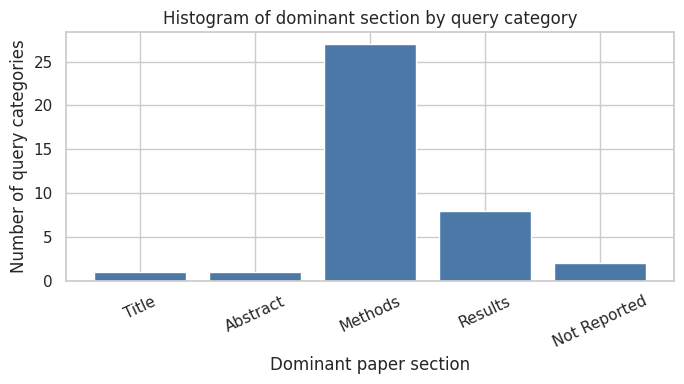

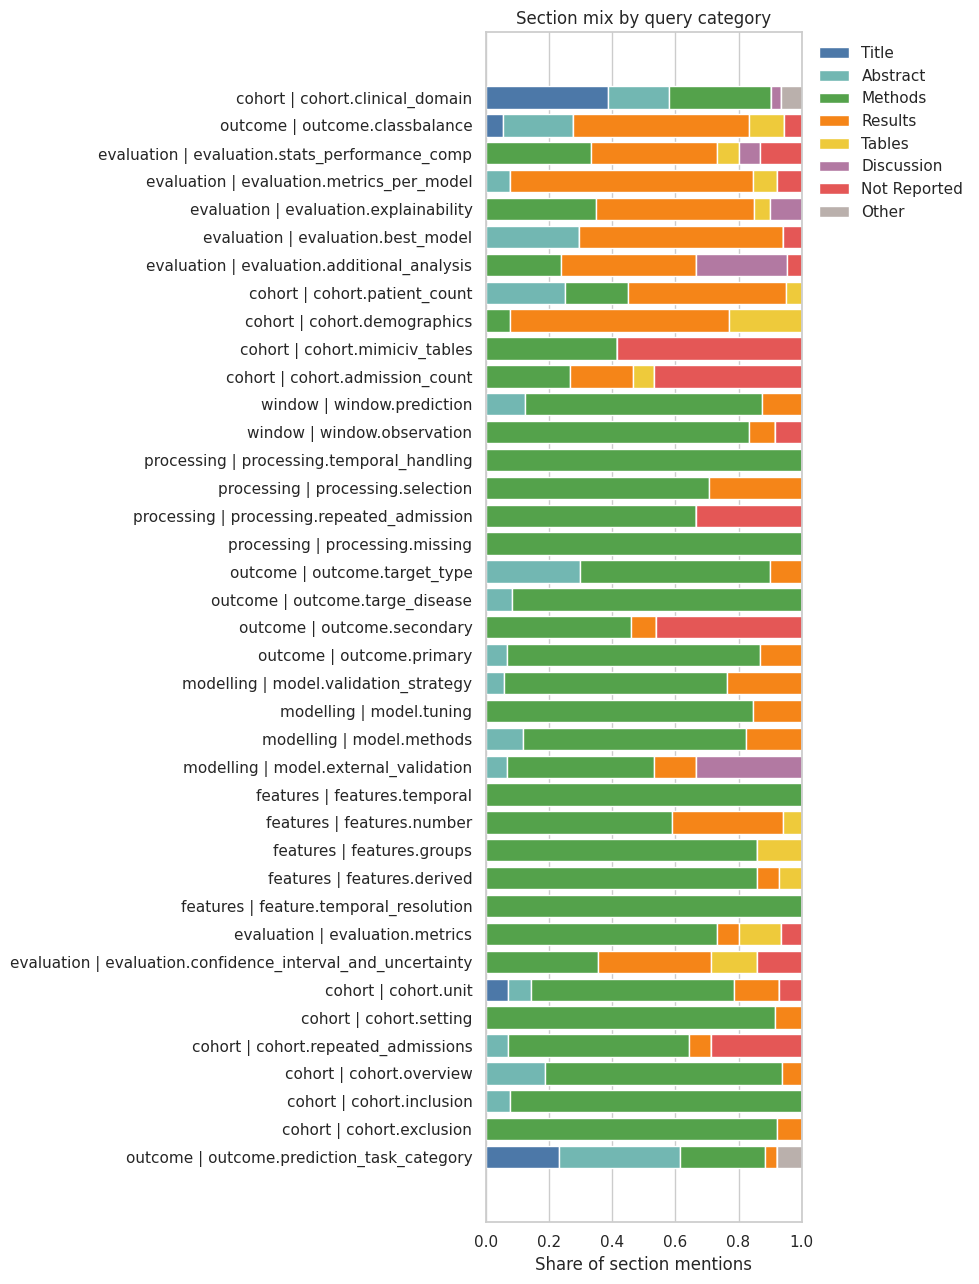

In [36]:
dominant_counts = (
    section_count_table["dominant_section"]
    .value_counts()
    .reindex(ordered_section_cols, fill_value=0)
    .reset_index()
)
dominant_counts.columns = ["section_family", "category_count"]

display(dominant_counts[dominant_counts["category_count"] > 0])

fig, ax = plt.subplots(figsize=(7, 4))
plot_counts = dominant_counts[dominant_counts["category_count"] > 0]
ax.bar(plot_counts["section_family"], plot_counts["category_count"], color="#4c78a8")
ax.set_xlabel("Dominant paper section")
ax.set_ylabel("Number of query categories")
ax.set_title("Histogram of dominant section by query category")
ax.tick_params(axis="x", rotation=25)
plt.tight_layout()

category_order = (
    section_count_table
    .sort_values(["dominant_section", "field_id", "category"])
    .index
)
stacked = section_share_table.loc[category_order, ordered_section_cols]

fig, ax = plt.subplots(figsize=(10, 13))
left = np.zeros(len(stacked))
colors = {
    "Title": "#4c78a8",
    "Abstract": "#72b7b2",
    "Methods": "#54a24b",
    "Results": "#f58518",
    "Tables": "#eeca3b",
    "Discussion": "#b279a2",
    "Supplementary": "#9d755d",
    "Not Reported": "#e45756",
    "Other": "#bab0ac",
}
for col in ordered_section_cols:
    values = stacked[col].to_numpy()
    ax.barh(
        [f"{field} | {category}" for field, category in stacked.index],
        values,
        left=left,
        label=col,
        color=colors.get(col, None),
    )
    left += values
ax.set_xlim(0, 1)
ax.set_xlabel("Share of section mentions")
ax.set_ylabel("")
ax.set_title("Section mix by query category")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()

## Compact Routing Table

This is a concise version for reporting: each category, its dominant section, and a practical retrieval hint.

In [37]:
category_section_map = section_count_table.reset_index()[
    ["field_id", "category", "dominant_section", "dominant_share", "total_mentions"]
].copy()
category_section_map["routing_hint"] = np.select(
    [
        category_section_map["dominant_section"].eq("Methods"),
        category_section_map["dominant_section"].eq("Results"),
        category_section_map["dominant_section"].isin(["Title", "Abstract"]),
        category_section_map["dominant_section"].eq("Tables"),
        category_section_map["dominant_section"].eq("Not Reported"),
    ],
    [
        "Retrieve Methods first",
        "Retrieve Results and table-adjacent chunks first",
        "Retrieve Title/Abstract first, then Methods",
        "Retrieve serialized tables and captions first",
        "Prompt for explicit not-reported handling",
    ],
    default="Use broad section retrieval",
)

display(
    category_section_map
    .sort_values(["field_id", "category"])
    .style.format({"dominant_share": "{:.1%}"})
)

section_family,field_id,category,dominant_section,dominant_share,total_mentions,routing_hint
0,cohort,cohort.admission_count,Not Reported,46.7%,15,Prompt for explicit not-reported handling
1,cohort,cohort.clinical_domain,Title,38.7%,31,"Retrieve Title/Abstract first, then Methods"
2,cohort,cohort.demographics,Results,69.2%,13,Retrieve Results and table-adjacent chunks first
3,cohort,cohort.exclusion,Methods,92.3%,13,Retrieve Methods first
4,cohort,cohort.inclusion,Methods,92.3%,13,Retrieve Methods first
5,cohort,cohort.mimiciv_tables,Not Reported,58.3%,12,Prompt for explicit not-reported handling
6,cohort,cohort.overview,Methods,75.0%,16,Retrieve Methods first
7,cohort,cohort.patient_count,Results,50.0%,20,Retrieve Results and table-adjacent chunks first
8,cohort,cohort.repeated_admissions,Methods,57.1%,14,Retrieve Methods first
9,cohort,cohort.setting,Methods,91.7%,12,Retrieve Methods first


## Finding

Across the 12 papers, the query categories are mostly Methods-oriented, with a smaller Results/table-oriented group and a few Title/Abstract or Not Reported categories. This supports a category-aware RAG strategy: route Methods-heavy questions to study-design, cohort, outcome-definition, feature-engineering, modelling, and preprocessing chunks; route Results-heavy questions to results and table-adjacent chunks; and handle Not Reported categories with explicit absence detection instead of forcing an inferred answer.